# 03 · Все кофейни Алматы из 2ГИС

Основной сбор (`03_2gis_data_safe.ipynb`) искал текстом «кофейня» в кругах 1 км вокруг 413 центров. У этого подхода три ограничения:
- круги покрывают около 69 % кандидатов;
- демо-ключ отдаёт не больше 50 заведений на запрос;
- текстовый поиск приносит кафе и кондитерские вперемешку с кофейнями.

Здесь мы собираем **все заведения по рубрикам 2ГИС**. В Алматы (`region_id = 67`) их столько (данные 2ГИС на 2026-11-21):

| рубрика | ID | филиалов |
|---|---|---|
| Кофейни | 162 | 1 100 |
| Точки кофе (кофе с собой) | 58871 | 570 |
| Кофейные автоматы | 112719 | 877 — не собираем: это не конкуренты кофейни |
| Продажа кофе | 558 | 364 — не собираем: это розница (зерно) |

**Как собираем.** Область «граница города + 1 км» делим на квадраты (квадродерево). Для каждого квадрата запрашиваем описанный вокруг него круг.
- Если 2ГИС сообщает больше 50 заведений, квадрат делится на 4.
- Если 50 или меньше, выкачиваем все страницы. Такой квадрат собран полностью (`complete`).
- В тех же запросах сразу приходят все нужные поля (рубрики, сеть, часы работы, атрибуты со средним чеком), поэтому догрузка по ID не нужна.

**Стоимость.** У демо-ключа 2ГИС общий лимит **1 000 запросов** к Places API на весь срок ключа (месяц). На ~1 600 заведений по 10 за страницу с перекрытием кругов уйдёт порядка 250–400 запросов. Сбор можно прерывать и продолжать: прогресс хранится в SQLite.

**Выходы** в `data/processed/2gis_coffee/` и `data/processed/features/`:
- `almaty_coffee_2gis.csv` — заведения: `id` (текст), рубрики, сеть, часы, рейтинг, средний чек и другие поля;
- `cells.csv`, `summary.json` — квадраты со статусами и число HTTP-попыток;
- `features/dgis_coffee_features.csv` — признаки кандидатов (`candidate_id, x, y, …`).

In [1]:
import json
from pathlib import Path
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import shapely

PROJECT_ROOT = (Path("..") if Path.cwd().name == "notebooks" else Path(".")).resolve()
sys.path.insert(0, str(PROJECT_ROOT / "notebooks"))
from dgis_api import (  # общий клиент 2ГИС: notebooks/dgis_api.py
    PLACES_URL, CollectionStopped, RubricSearch, classify, coffee_features, collect_area, covered_by_squares,
    load_area, parse_item, read_api_key,
)

BOUNDARY_PATH = PROJECT_ROOT / "data" / "processed" / "almaty_boundary.gpkg"
CANDIDATES_PATH = PROJECT_ROOT / "data" / "processed" / "candidate_locations.gpkg"
OUT_DIR = PROJECT_ROOT / "data" / "processed" / "2gis_coffee"
CHECKPOINT = OUT_DIR / "coffee_progress.sqlite3"
PLACES_CSV = OUT_DIR / "almaty_coffee_2gis.csv"
CELLS_CSV = OUT_DIR / "cells.csv"
SUMMARY_JSON = OUT_DIR / "summary.json"
FEATURES_CSV = PROJECT_ROOT / "data" / "processed" / "features" / "dgis_coffee_features.csv"
OTHER_SEARCHES = {  # другие сборы — только для сравнения
    "main": PROJECT_ROOT / "data" / "processed" / "2gis_almaty_progress.sqlite3",
    "gap": PROJECT_ROOT / "data" / "processed" / "2gis_gap" / "gap_progress.sqlite3",
}

CRS_METRIC = "EPSG:32643"
N_CANDIDATES = 2822
REGION_ID = 67                                   # Алматы в 2ГИС (items.region_id)
RUBRICS = {162: "Кофейни", 58871: "Точки кофе"}
AREA_BUFFER_M = 1000                             # круг 500 м вокруг кандидатов у границы тоже внутри области
MIN_SIDE_M = 250                                 # мельче квадраты не делим; если и там > 50 — статус capped
FEATURE_RADIUS_M = 500
CHAIN_MIN_BRANCHES = 3

SEARCH = RubricSearch(rubric_ids=tuple(RUBRICS), region_id=REGION_ID, min_side_m=MIN_SIDE_M)

In [2]:
if not BOUNDARY_PATH.is_file():
    raise FileNotFoundError("Нет data/processed/almaty_boundary.gpkg — запустите 02_candidate_locations.ipynb.")
city = gpd.read_file(BOUNDARY_PATH).to_crs(CRS_METRIC)
area = shapely.union_all(city.buffer(AREA_BUFFER_M).to_numpy())
minx, miny, maxx, maxy = area.bounds
root_side = max(maxx - minx, maxy - miny)
print(f"Область: {area.area / 1e6:.0f} км², корневой квадрат {root_side / 1000:.1f} км, "
      f"радиус корневого круга {root_side * 2 ** 0.5 / 2 / 1000:.1f} км (предел 2ГИС — 50 км)")
print("Параметры поиска:", {k: v for k, v in SEARCH.params().items() if k != "fields"})

Область: 905 км², корневой квадрат 43.2 км, радиус корневого круга 30.5 км (предел 2ГИС — 50 км)
Параметры поиска: {'rubric_id': '162,58871', 'region_id': 67, 'type': 'branch', 'page_size': 10}


In [3]:
import tempfile
import unittest
from unittest.mock import Mock

from pyproj import Transformer


class FakeDGIS:
    """Имитация /3.0/items: круг point+radius, total и страницы, как у 2ГИС (порядок — по id)."""

    def __init__(self, xy, crs=CRS_METRIC):
        self.to_lonlat = Transformer.from_crs(crs, "EPSG:4326", always_xy=True)
        self.to_metric = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
        self.xy = np.asarray(xy, dtype=float)
        lon, lat = self.to_lonlat.transform(self.xy[:, 0], self.xy[:, 1])
        self.places = [{"id": str(70000001000000000 + i), "name": f"place {i}", "point": {"lon": lo, "lat": la},
                        "rubrics": [{"id": "162", "name": "Кофейни", "kind": "primary"}]}
                       for i, (lo, la) in enumerate(zip(lon, lat))]
        self.calls = []

    def __call__(self, url, params, timeout, allow_redirects):
        self.calls.append(dict(params))
        lon, lat = map(float, params["point"].split(","))
        cx, cy = self.to_metric.transform(lon, lat)
        inside = np.flatnonzero(np.hypot(self.xy[:, 0] - cx, self.xy[:, 1] - cy) <= params["radius"])
        page, size = params["page"], params["page_size"]
        items = [self.places[i] for i in inside[(page - 1) * size: page * size]]
        data = {"meta": {"code": 200}, "result": {"items": items, "total": len(inside)}}
        return Mock(status_code=200, headers={"Retry-After": None}, **{"json.return_value": data})


class AreaCollectorTests(unittest.TestCase):
    X0, Y0 = 650_000.0, 4_785_000.0

    def setUp(self):
        temp = tempfile.TemporaryDirectory()
        self.addCleanup(temp.cleanup)
        self.checkpoint = Path(temp.name) / "area.sqlite3"
        self.clock = 1_700_000_000.0
        rng = np.random.default_rng(7)
        dense = rng.normal([self.X0 + 1500, self.Y0 + 1500], 120, size=(140, 2))        # плотный центр
        sparse = rng.uniform([self.X0, self.Y0], [self.X0 + 4000, self.Y0 + 4000], size=(160, 2))
        outside = rng.uniform([self.X0 + 6000, self.Y0], [self.X0 + 8000, self.Y0 + 2000], size=(30, 2))
        self.fake = FakeDGIS(np.vstack([dense, sparse, outside]))
        self.area = shapely.box(self.X0, self.Y0, self.X0 + 4000, self.Y0 + 4000)

    def sleep(self, seconds):
        self.clock += seconds

    def collect(self, *, limit=2000, search=None, area=None, get=None):
        return collect_area(search or RubricSearch(rubric_ids=(162, 58871), region_id=67, min_side_m=100),
                            self.checkpoint, area=area or self.area, crs=CRS_METRIC, key="mock-credential",
                            get=get or self.fake, max_requests_total=limit, now=lambda: self.clock, sleep=self.sleep)

    def inside_ids(self, area):
        return {p["id"] for p, (x, y) in zip(self.fake.places, self.fake.xy) if area.covers(shapely.Point(x, y))}

    def test_every_place_in_area_is_collected(self):
        result = self.collect()
        items, cells, _ = load_area(self.checkpoint)
        self.assertIsNone(result["stop_reason"])
        self.assertTrue(self.inside_ids(self.area) <= {it["id"] for it in items})
        leaves = [c for c in cells if c["status"] != "split"]
        self.assertTrue(all(c["status"] == "complete" for c in leaves))
        self.assertGreater(result["max_depth"], 1)                  # плотный центр пришлось делить
        self.assertEqual(result["attempts"], len(self.fake.calls))
        first = self.fake.calls[0]
        self.assertEqual((first["rubric_id"], first["region_id"], first["type"]), ("162,58871", 67, "branch"))
        self.assertIn("items.attribute_groups", first["fields"])
        # листья покрывают область целиком
        union = shapely.union_all([shapely.box(c["x0"], c["y0"], c["x0"] + c["side"], c["y0"] + c["side"]) for c in leaves])
        self.assertTrue(union.covers(self.area))

    def test_capped_when_cannot_split(self):
        fake = FakeDGIS(np.full((80, 2), [self.X0 + 2000, self.Y0 + 2000]))   # 80 мест в одной точке
        result = self.collect(get=fake, search=RubricSearch(rubric_ids=(162,), region_id=67, min_side_m=3000))
        self.assertEqual(result["cells"]["capped"], 1)
        self.assertEqual(result["items"], 50)

    def test_resume_after_budget_stop_without_repeats(self):
        once = self.collect()
        calls_once = len(self.fake.calls)
        self.checkpoint.unlink()
        self.fake.calls.clear()
        stopped = self.collect(limit=7)
        self.assertIn("лимит", stopped["stop_reason"])
        resumed = self.collect(limit=2000)
        self.assertEqual(len(self.fake.calls), calls_once)
        self.assertEqual((resumed["items"], resumed["attempts"]), (once["items"], once["attempts"]))

    def test_changed_plan_is_rejected(self):
        self.collect(limit=3)
        with self.assertRaisesRegex(CollectionStopped, "План сбора изменился"):
            self.collect(search=RubricSearch(rubric_ids=(162,), region_id=67, min_side_m=100))

    def test_cells_outside_area_are_skipped(self):
        l_shape = shapely.union_all([shapely.box(self.X0, self.Y0, self.X0 + 4000, self.Y0 + 1000),
                                     shapely.box(self.X0, self.Y0, self.X0 + 1000, self.Y0 + 4000)])
        result = self.collect(area=l_shape)
        _, cells, _ = load_area(self.checkpoint)
        self.assertTrue(all(l_shape.intersects(shapely.box(c["x0"], c["y0"], c["x0"] + c["side"], c["y0"] + c["side"]))
                            for c in cells))
        items, _, _ = load_area(self.checkpoint)
        self.assertTrue(self.inside_ids(l_shape) <= {it["id"] for it in items})

    def test_too_large_area_is_rejected(self):
        with self.assertRaises(ValueError):
            self.collect(area=shapely.box(self.X0, self.Y0, self.X0 + 80_000, self.Y0 + 1000))

    def test_features_and_coverage(self):
        x0, y0 = self.X0, self.Y0
        candidates = gpd.GeoDataFrame({"candidate_id": [10, 11, 12]},
                                      geometry=gpd.points_from_xy([x0, x0 + 1000, x0 + 5000], [y0] * 3), crs=CRS_METRIC)
        shops = classify(pd.DataFrame({
            "rubric_names": ["Кофейни", "Кондитерские;Кофейни", "Кофейни", "Рестораны"],
            "org_branch_count": [5, 1, None, 40], "brand_branch_count": [None, None, None, None],
            "opens_by_8": [True, False, False, True], "general_rating": [4.0, 5.0, None, 3.0],
            "general_review_count": [10, 30, None, 100], "avg_check_kzt": [3000, 5000, None, 9000],
        }), {"Кофейни"}, 3)
        self.assertEqual(shops["is_coffee"].tolist(), [True, True, True, False])
        self.assertEqual(shops["is_chain"].tolist(), [True, False, False, True])
        coffee = gpd.GeoDataFrame(shops[shops["is_coffee"]],
                                  geometry=gpd.points_from_xy([x0 + 100, x0 + 400, x0 + 1300], [y0] * 3), crs=CRS_METRIC)
        feats = coffee_features(candidates, coffee, 500).set_index("candidate_id")
        self.assertEqual(feats["dgis_coffee_500m"].tolist(), [2, 1, 0])
        self.assertEqual(feats["dgis_coffee_chain_500m"].tolist(), [1, 0, 0])
        self.assertEqual(feats["dgis_coffee_early_500m"].tolist(), [1, 0, 0])
        self.assertEqual(feats["dgis_coffee_reviews_500m"].tolist(), [40, 0, 0])
        self.assertEqual(feats.loc[10, "dgis_coffee_rating_mean_500m"], 4.5)
        self.assertEqual(feats.loc[10, "dgis_coffee_avg_check_median_500m"], 4000)
        self.assertTrue(np.isnan(feats.loc[11, "dgis_coffee_rating_mean_500m"]))
        self.assertTrue(np.isnan(feats.loc[12, "dgis_coffee_avg_check_median_500m"]))
        cells = [{"x0": x0 - 1000, "y0": y0 - 1000, "side": 2000, "status": "complete"},
                 {"x0": x0 + 1000, "y0": y0 - 1000, "side": 2000, "status": "capped"}]
        self.assertEqual(covered_by_squares(candidates, cells, 500).tolist(), [True, False, False])
        # квадрат, разбитый на 4 с «некруглыми» координатами: стыки не должны давать ложное «неполно»
        side = 1348.0404399
        quads = [{"x0": x0 - side + dx, "y0": y0 - side + dy, "side": side, "status": "complete"}
                 for dx in (0, side) for dy in (0, side)]
        self.assertTrue(covered_by_squares(candidates.iloc[[0]], quads, 500).all())


suite = unittest.defaultTestLoader.loadTestsFromTestCase(AreaCollectorTests)
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
if not test_result.wasSuccessful():
    raise AssertionError("Проверки сбора по рубрикам завершились ошибкой.")

test_capped_when_cannot_split (__main__.AreaCollectorTests.test_capped_when_cannot_split) ... 

ok


test_cells_outside_area_are_skipped (__main__.AreaCollectorTests.test_cells_outside_area_are_skipped) ... 

ok


test_changed_plan_is_rejected (__main__.AreaCollectorTests.test_changed_plan_is_rejected) ... 

ok


... (5 outputs left out)

ok


test_too_large_area_is_rejected (__main__.AreaCollectorTests.test_too_large_area_is_rejected) ... 

ok


----------------------------------------------------------------------
Ran 7 tests in 7.060s

OK


## Сбор

1. Ключ лежит в `.env` строкой `DGIS_API_KEY=...`.
2. **Пробный запуск.** `RUN_LIVE = True`, `MAX_REQUESTS_TOTAL = 30`. Проверьте, что поля пришли и квадраты делятся.
3. **Полный сбор.** `MAX_REQUESTS_TOTAL = 500` (это лимит с учётом уже потраченных попыток). Если сбор остановится на лимите, увеличьте его и запустите снова: готовые квадраты повторно не запрашиваются.

In [4]:
RUN_LIVE = False
MAX_REQUESTS_TOTAL = 30    # пробный запуск; для полного сбора — 500
MIN_INTERVAL_SECONDS = 1.0

if RUN_LIVE:
    with requests.Session() as session:
        run_result = collect_area(SEARCH, CHECKPOINT, area=area, crs=CRS_METRIC, key=read_api_key(PROJECT_ROOT),
                                  get=session.get, max_requests_total=MAX_REQUESTS_TOTAL, interval=MIN_INTERVAL_SECONDS)
    print(run_result)
else:
    print("Запросы к 2ГИС выключены (RUN_LIVE = False).")

Запросы к 2ГИС выключены (RUN_LIVE = False).


## Результат сбора

Каждый ответ раскладывается в строку таблицы, затем отмечаются рубрики:
- `is_coffee_shop` — рубрика «Кофейни»;
- `is_coffee_point` — «Точки кофе».

`in_area` показывает, что заведение лежит внутри области. Круги по краям захватывают и заведения за её пределами, а в таблицу попадают только `in_area`.

In [5]:
places, cells_df = None, None
if CHECKPOINT.is_file():
    items, cells, summary = load_area(CHECKPOINT)
    cells_df = pd.DataFrame(cells)
    pending = int((cells_df["status"] == "pending").sum())
    print(summary)
    places = pd.DataFrame([parse_item(item) for item in items])
    places = places.astype({"org_branch_count": "Int64", "brand_branch_count": "Int64", "general_review_count": "Int64",
                            "avg_check_kzt": "Int64", "seats_max": "Int64"})
    rubric_sets = places["rubric_names"].fillna("").str.split(";").map(set)
    places["is_coffee_shop"] = rubric_sets.map(lambda r: RUBRICS[162] in r)
    places["is_coffee_point"] = rubric_sets.map(lambda r: RUBRICS[58871] in r)
    places = classify(places, set(RUBRICS.values()), CHAIN_MIN_BRANCHES)
    geom = gpd.GeoSeries(gpd.points_from_xy(places["lon"], places["lat"]), crs="EPSG:4326").to_crs(CRS_METRIC)
    places["x"], places["y"] = geom.x.round(2).to_numpy(), geom.y.round(2).to_numpy()
    places["in_area"] = shapely.covers(area, geom.to_numpy())
    print(f"Ответов: {len(places)}, внутри области: {places['in_area'].sum()}, без координат: {places['lon'].isna().sum()}")
    places = places[places["in_area"]].drop(columns="in_area").sort_values("id").reset_index(drop=True)
    assert places["id"].is_unique

    OUT_DIR.mkdir(parents=True, exist_ok=True)
    places.to_csv(PLACES_CSV, index=False, lineterminator="\n")
    cells_df.to_csv(CELLS_CSV, index=False, lineterminator="\n")
    SUMMARY_JSON.write_text(json.dumps(summary | {"pending_cells": pending, "places_in_area": len(places)},
                                       ensure_ascii=False, indent=2, sort_keys=True) + "\n", encoding="utf-8")
    print(f"Сохранено: {PLACES_CSV.relative_to(PROJECT_ROOT)} ({len(places)} строк)")
    print("Квадраты:", cells_df["status"].value_counts().to_dict(), "| глубина:", cells_df["depth"].value_counts().sort_index().to_dict())
    print("По рубрикам:", {"Кофейни": int(places["is_coffee_shop"].sum()), "Точки кофе": int(places["is_coffee_point"].sum()),
                           "обе": int((places["is_coffee_shop"] & places["is_coffee_point"]).sum())})
    print("Доли:", places[["is_chain", "opens_by_8", "open_24x7", "temporary_closed", "coffee_to_go", "free_wifi",
                           "laptop_friendly"]].mean().round(3).to_dict())
    print("Средний чек, ₸:", places["avg_check_kzt"].describe().round(0).to_dict())
    if pending:
        print(f"Сбор не завершён: осталось {pending} квадратов. Увеличьте MAX_REQUESTS_TOTAL и запустите сбор снова.")
    capped = cells_df[cells_df["status"].isin(["capped", "short"])]
    if len(capped):
        display(capped)
else:
    print("Файла прогресса ещё нет: запустите сбор.")

{'attempts': 384, 'cells': {'pending': 0, 'split': 44, 'complete': 131, 'capped': 0, 'short': 1}, 'max_depth': 6, 'items': 1517}
Ответов: 1517, внутри области: 1461, без координат: 0


Сохранено: data\processed\2gis_coffee\almaty_coffee_2gis.csv (1461 строк)
Квадраты: {'complete': 131, 'split': 44, 'short': 1} | глубина: {0: 1, 1: 4, 2: 11, 3: 24, 4: 36, 5: 44, 6: 56}
По рубрикам: {'Кофейни': 971, 'Точки кофе': 490, 'обе': 0}
Доли: {'is_chain': 0.398, 'opens_by_8': 0.678, 'open_24x7': 0.047, 'temporary_closed': 0.016, 'coffee_to_go': 0.863, 'free_wifi': 0.422, 'laptop_friendly': 0.381}
Средний чек, ₸: {'count': 766.0, 'mean': 3037.0, 'std': 1812.0, 'min': 700.0, '25%': 1800.0, '50%': 2500.0, '75%': 3500.0, 'max': 15000.0}


,cell_id,depth,x0,y0,side,point,radius_m,status,next_page,expected_total
28,r032302,6,653757.028448,4.784960e+06,674.52022,"76.896821,43.204735",479,short,6,44


## Сравнение с другими сборами

Если рядом лежат файлы основного сбора по тексту «кофейня» и догрузки 18 точек, смотрим, сколько их заведений вошло в рубричный сбор. Заведения, которых здесь нет, — это кафе, кондитерские и т. п. без рубрик «Кофейни» и «Точки кофе».

In [6]:
import sqlite3
from contextlib import closing

if places is not None:
    for name, path in OTHER_SEARCHES.items():
        if not path.is_file():
            print(f"{name}: нет файла {path.relative_to(PROJECT_ROOT)}")
            continue
        with closing(sqlite3.connect(path.resolve().as_uri() + "?mode=ro", uri=True)) as db:
            other = pd.read_sql_query("SELECT id, name FROM organizations", db)
        shared = other["id"].isin(places["id"])
        print(f"{name}: {len(other)} заведений, из них в рубричном сборе {shared.sum()}; нет: {(~shared).sum()}")
        if (~shared).any():
            print("   примеры не вошедших:", other.loc[~shared, "name"].head(8).tolist())

main: нет файла data\processed\2gis_almaty_progress.sqlite3
gap: 7 заведений, из них в рубричном сборе 7; нет: 0


## Признаки для кандидатов

Признаки считаются, только когда сбор завершён (нет квадратов `pending`). Временно закрытые заведения не учитываются. Признаки в радиусе 500 м:

| признак | смысл |
|---|---|
| `dgis_coffee_500m` | кофейни (рубрика «Кофейни») |
| `dgis_coffee_chain_500m` | из них сетевые: от 3 филиалов у организации или бренда |
| `dgis_coffee_early_500m` | из них открытые к 8:00 в будни |
| `dgis_coffee_reviews_500m` | сумма их отзывов — показатель потока посетителей |
| `dgis_coffee_rating_mean_500m` | средний рейтинг кофеен; пустой, если кофеен рядом нет |
| `dgis_coffee_avg_check_median_500m` | медианный средний чек, ₸ — ценовой сегмент района; пустой, если чека нет |
| `dgis_coffee_points_500m` | «Точки кофе» без рубрики «Кофейни» — кофе с собой, киоски |
| `dgis_search_complete_500m` | круг 500 м целиком внутри квадратов `complete` |

In [7]:
features = None
if places is not None and pending == 0:
    grid = gpd.read_file(CANDIDATES_PATH)
    if "candidate_id" not in grid.columns:
        raise ValueError("В candidate_locations.gpkg нет столбца candidate_id. Пересоберите сетку через 02.")
    grid = grid[["candidate_id", "geometry"]].to_crs(CRS_METRIC)
    assert len(grid) == N_CANDIDATES and grid["candidate_id"].is_unique

    open_places = places[~places["temporary_closed"] & places["lon"].notna()]
    open_places = gpd.GeoDataFrame(open_places, geometry=gpd.points_from_xy(open_places["x"], open_places["y"]),
                                   crs=CRS_METRIC)
    shops = open_places[open_places["is_coffee_shop"]]
    points_only = open_places[open_places["is_coffee_point"] & ~open_places["is_coffee_shop"]]
    features = coffee_features(grid, shops, FEATURE_RADIUS_M, prefix="dgis_coffee")
    cand_pos, _ = points_only.sindex.query(grid.geometry, predicate="dwithin", distance=FEATURE_RADIUS_M)
    features[f"dgis_coffee_points_{FEATURE_RADIUS_M}m"] = np.bincount(cand_pos, minlength=len(grid))
    complete_col = f"dgis_search_complete_{FEATURE_RADIUS_M}m"
    features[complete_col] = covered_by_squares(grid, cells, FEATURE_RADIUS_M)
    # x/y без округления — как в признаках OSM, для проверки при объединении по candidate_id
    features.insert(1, "x", grid.geometry.x.to_numpy())
    features.insert(2, "y", grid.geometry.y.to_numpy())
    assert len(features) == N_CANDIDATES and features["candidate_id"].is_unique
    FEATURES_CSV.parent.mkdir(parents=True, exist_ok=True)
    features.to_csv(FEATURES_CSV, index=False, lineterminator="\n")
    print(f"Кофеен: {len(shops)}, точек кофе: {len(points_only)}; сохранено: {FEATURES_CSV.relative_to(PROJECT_ROOT)}")
    print(f"Круг {FEATURE_RADIUS_M} м покрыт полным сбором у {features[complete_col].sum()} из {len(features)} точек")
    display(features.drop(columns=["candidate_id", "x", "y"]).describe().T)
    print("NaN:", features.isna().sum()[lambda s: s > 0].to_dict())
elif places is not None:
    print("Сбор не завершён — признаки не считаю.")

Кофеен: 954, точек кофе: 483; сохранено: data\processed\features\dgis_coffee_features.csv
Круг 500 м покрыт полным сбором у 2811 из 2822 точек


,count,mean,std,min,25%,50%,75%,max
dgis_coffee_500m,2822.0,1.046067,3.339154,0.0,0.00000,0.0,0.000,31.0
dgis_coffee_chain_500m,2822.0,0.501772,1.836984,0.0,0.00000,0.0,0.000,22.0
dgis_coffee_early_500m,2822.0,0.770021,2.552098,0.0,0.00000,0.0,0.000,25.0
dgis_coffee_reviews_500m,2822.0,405.920978,1727.861605,0.0,0.00000,0.0,0.000,25161.0
dgis_coffee_rating_mean_500m,620.0,4.697834,0.405364,1.3,4.68225,4.8,4.875,5.0
dgis_coffee_avg_check_median_500m,529.0,2639.810964,1115.288878,700.0,1850.00000,2500.0,3000.000,7500.0
dgis_coffee_points_500m,2822.0,0.531892,1.755594,0.0,0.00000,0.0,0.000,19.0


NaN: {'dgis_coffee_rating_mean_500m': 2202, 'dgis_coffee_avg_check_median_500m': 2293}


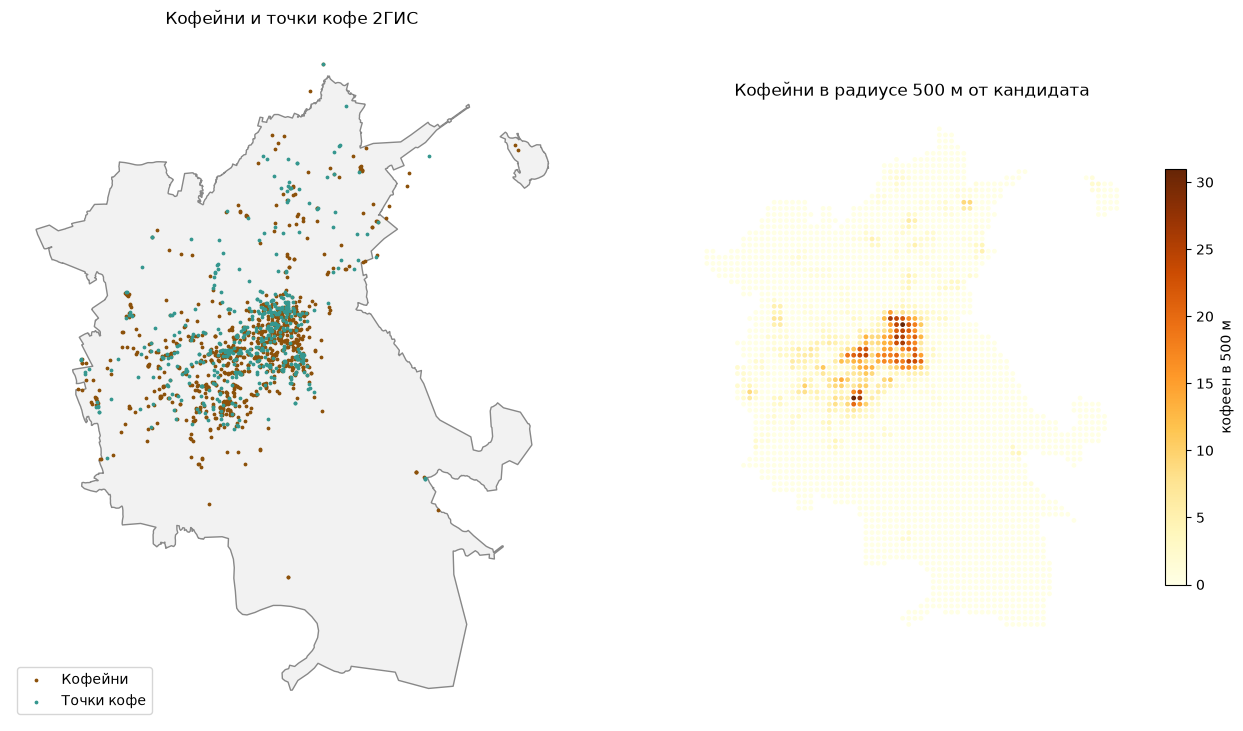

In [8]:
if features is not None:
    col = f"dgis_coffee_{FEATURE_RADIUS_M}m"
    plot = grid.merge(features[["candidate_id", col]], on="candidate_id", validate="one_to_one")
    fig, axes = plt.subplots(1, 2, figsize=(16, 9))
    city.plot(ax=axes[0], color="#f2f2f2", edgecolor="#888888")
    shops.plot(ax=axes[0], markersize=3, color="#8c510a", label="Кофейни")
    points_only.plot(ax=axes[0], markersize=3, color="#35978f", label="Точки кофе")
    axes[0].legend(loc="lower left")
    axes[0].set_title("Кофейни и точки кофе 2ГИС")
    plot.plot(ax=axes[1], column=col, cmap="YlOrBr", markersize=6, legend=True,
              legend_kwds={"label": f"кофеен в {FEATURE_RADIUS_M} м", "shrink": 0.6})
    axes[1].set_title(f"Кофейни в радиусе {FEATURE_RADIUS_M} м от кандидата")
    for ax in axes:
        ax.set_axis_off()
    plt.show()